In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(
    "../data/processed/cleaned_customer_churn.csv"
)

print("Dataset Shape:", df.shape)

Dataset Shape: (7043, 21)


In [2]:
df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=[
        "0-12 Months",
        "13-24 Months",
        "25-48 Months",
        "49-72 Months"
    ]
)

df[["customerID", "tenure", "TenureGroup", "Churn"]].head()

,customerID,tenure,TenureGroup,Churn
0,7590-VHVEG,1,0-12 Months,No
1,5575-GNVDE,34,25-48 Months,No
2,3668-QPYBK,2,0-12 Months,Yes
3,7795-CFOCW,45,25-48 Months,No
4,9237-HQITU,2,0-12 Months,Yes


In [3]:
retention_analysis = df.groupby(
    "TenureGroup",
    observed=False
).agg(
    Total_Customers=("customerID", "count"),
    Churned_Customers=(
        "Churn",
        lambda x: (x == "Yes").sum()
    )
)

retention_analysis["Churn_Rate"] = (
    retention_analysis["Churned_Customers"] /
    retention_analysis["Total_Customers"]
) * 100

retention_analysis["Retention_Rate"] = (
    100 - retention_analysis["Churn_Rate"]
)

retention_analysis.round(2)

,Total_Customers,Churned_Customers,Churn_Rate,Retention_Rate
TenureGroup,,,,
0-12 Months,2186,1037,47.44,52.56
13-24 Months,1024,294,28.71,71.29
25-48 Months,1594,325,20.39,79.61
49-72 Months,2239,213,9.51,90.49


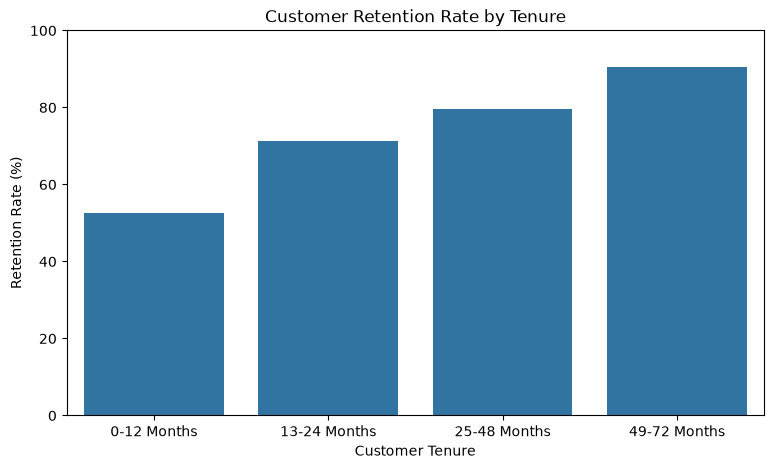

In [4]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=retention_analysis.reset_index(),
    x="TenureGroup",
    y="Retention_Rate"
)

plt.title("Customer Retention Rate by Tenure")
plt.xlabel("Customer Tenure")
plt.ylabel("Retention Rate (%)")
plt.ylim(0, 100)

plt.show()

In [5]:
churned_customers = df[df["Churn"] == "Yes"]

monthly_revenue_lost = churned_customers[
    "MonthlyCharges"
].sum()

print(
    "Estimated Monthly Revenue Lost:",
    round(monthly_revenue_lost, 2)
)

print(
    "Average Monthly Charges of Churned Customers:",
    round(churned_customers["MonthlyCharges"].mean(), 2)
)

Estimated Monthly Revenue Lost: 139130.85
Average Monthly Charges of Churned Customers: 74.44


In [6]:
contract_retention = df.groupby(
    "Contract"
).agg(
    Total_Customers=("customerID", "count"),
    Churned_Customers=(
        "Churn",
        lambda x: (x == "Yes").sum()
    )
)

contract_retention["Retention_Rate"] = (
    1 -
    contract_retention["Churned_Customers"] /
    contract_retention["Total_Customers"]
) * 100

contract_retention.round(2)

,Total_Customers,Churned_Customers,Retention_Rate
Contract,,,
Month-to-month,3875,1655,57.29
One year,1473,166,88.73
Two year,1695,48,97.17


In [7]:
retention_analysis.to_csv(
    "../reports/tenure_retention_analysis.csv"
)

contract_retention.to_csv(
    "../reports/contract_retention_analysis.csv"
)

print("Retention reports exported successfully!")

Retention reports exported successfully!
